## exercice 1 :

In [41]:
import cv2 
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

In [42]:
def to_grayscale(image):
    if len(image.shape) == 2:
        gray = image
    else: 
        b,g,r = cv2.split(image)
        gray = 0.114*b + 0.587*g + 0.299*r
    
    if gray.dtype != np.uint8:
        gray = np.clip(gray,0,255).astype(np.uint8)
    return gray

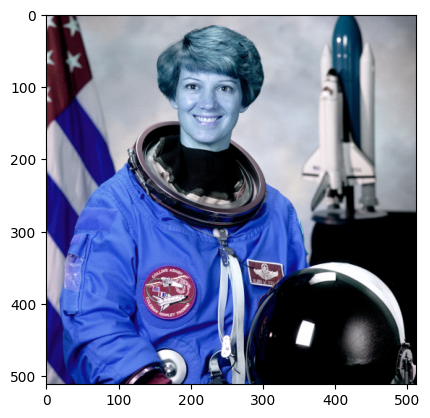

In [59]:
img = data.astronaut()
# affichage de l'image originale
plt.imshow(cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

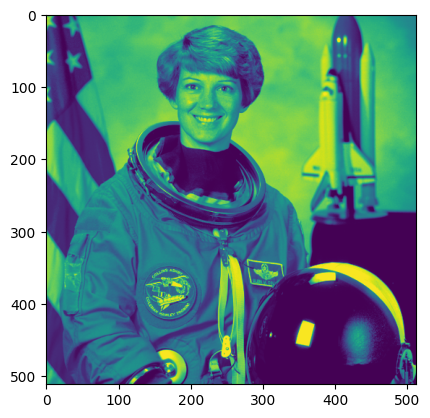

In [60]:
# conversion en niveaux de gris et affichage
gray_img = to_grayscale(img)
plt.imshow(gray_img)

## Exercice 2 : 

In [61]:
def seuillage_fixe(image_gray , T):
    if T < 0 or T > 255:
        raise ValueError("Le seuil doit être compris entre 0 et 255")
    for i in range(len(image_gray)):
        for j in range(len(image_gray[0])):
            if image_gray[i][j] < T :
                image_gray[i][j] = 0
            else:
                image_gray[i][j] = 255
    
    return image_gray

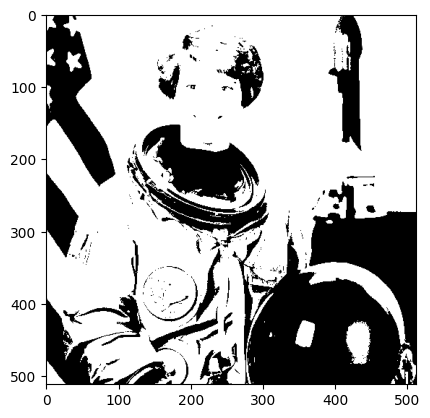

In [62]:
seuil = 64
binary_img = seuillage_fixe(gray_img.copy(), seuil)
plt.imshow(binary_img, cmap='gray')

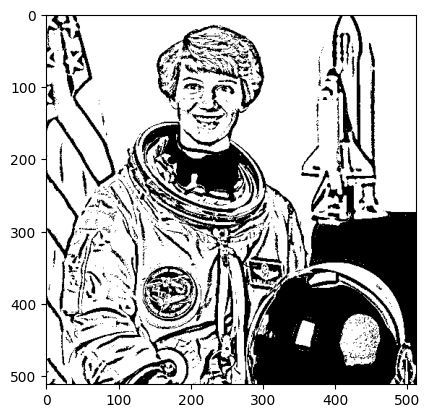

In [63]:
## Exercice 3 
def threshold_adaptive_mean(img , block_size , C):
    if img.dtype != np.uint8:
        raise ValueError("L'image doit être au format uint8.")
    if block_size < 3 or block_size % 2 == 0:
        raise ValueError("block_size doit être un entier impair ≥ 3.")
    

    meanlocal = cv2.blur(img , (block_size , block_size))
    image_binaire = np.zeros(img.shape, dtype=np.uint8)
    image_binaire[img > (meanlocal - C)] = 255
    return image_binaire

adaptive_img = threshold_adaptive_mean(gray_img , 11 , 10)
plt.imshow(adaptive_img , cmap='gray')

Seuil optimal selon Otsu : 103


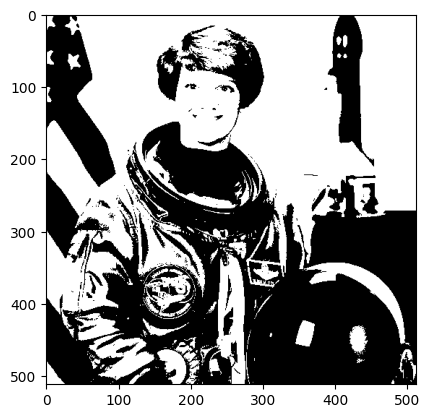

In [64]:
# Exercice 4
def threshold_otsu(img_gray: np.ndarray) -> tuple[np.ndarray, int]:

    if img_gray.dtype != np.uint8:
        raise ValueError("L'image doit être uint8.")
    sigma_max = 0
    T_optimal = 0
    for T in range(1, 255):

        C0 = img_gray[img_gray <= T]
        C1 = img_gray[img_gray > T]

        w0 = C0.size / img_gray.size
        w1 = C1.size / img_gray.size
        
        if C0.size == 0 or C1.size == 0:
            continue
        u0 = np.mean(C0)
        u1 = np.mean(C1)

        sigma = w0 * w1 * (u0 - u1) **2
        if sigma > sigma_max:
            sigma_max = sigma
            T_optimal = T
        
        binary = np.zeros(img_gray.shape, dtype=np.uint8)
        binary[img_gray > T_optimal] = 255

    return binary, T_optimal    
    
otsu_img, T_otsu = threshold_otsu(gray_img)
print("Seuil optimal selon Otsu :", T_otsu)
plt.imshow(otsu_img , cmap='gray')

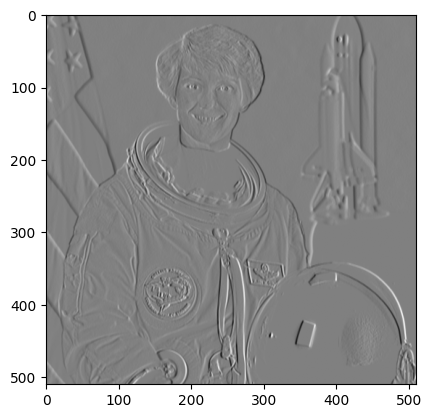

In [67]:
def convolution_2d(img: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    h_img , w_img = img.shape
    h_k , w_k = kernel.shape
    kx ,ky = h_k // 2 , w_k // 2 

    output = np.zeros((h_img - 2 * kx , w_img - 2 * ky))
    for i in range(kx, h_img - kx):
        for j in range(ky, w_img - ky):
            region = img[i - kx : i + kx + 1, j - ky : j + ky + 1]
            value = np.sum(region * kernel)
            output[i - kx, j - ky] = value

    return output

# Exemple d'utilisation de la fonction de convolution
kernel = np.array([[1, 0, -1],
                   [1, 0, -1],
                   [1, 0, -1]]) / 9
convolved_img = convolution_2d(gray_img, kernel)
plt.imshow(convolved_img, cmap='gray')



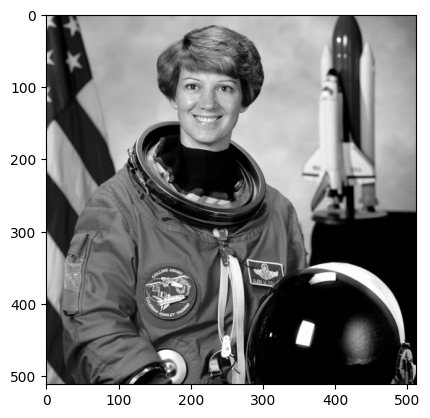

In [70]:
plt.imshow(img)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(img_gray, cmap='gray')